In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from statistics import mode
#!pip install seaborn --upgrade

%matplotlib inline

In [18]:
df = pd.read_csv(r"C:\Users\ramya\Downloads\archive (16)\amz_uk_price_prediction_dataset.csv")

df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


# Part 1: 

## Analyzing Best-Seller Trends Across Product Categories
**Objective: Understand the relationship between product categories and their best-seller status.**

**Crosstab Analysis:**

- Create a crosstab between the product category and the isBestSeller status.
- Are there categories where being a best-seller is more prevalent?
- Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.

**Statistical Tests:**

- Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
- Compute Cramér's V to understand the strength of association between best-seller status and category.

**Visualizations:**

- Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

In [4]:
crosstab_result = pd.crosstab(df['category'], df['isBestSeller']).sort_values(True, ascending = False)
crosstab_result

isBestSeller,False,True
category,,
Grocery,9008,556
Health & Personal Care,9017,552
Baby,14709,341
Sports & Outdoors,835935,330
Power & Hand Tools,8353,306
...,...,...
Downhill Ski Boots,1284,0
Digital Frames,774,0
Motorbike Chassis,107,0


In [5]:
table = crosstab_result.div(crosstab_result.sum(axis=1), axis=0).sort_values(True, ascending = False)
table

isBestSeller,False,True
category,,
Grocery,0.941865,0.058135
Smart Home Security & Lighting,0.942308,0.057692
Health & Personal Care,0.942314,0.057686
Mobile Phone Accessories,0.957529,0.042471
Power & Hand Tools,0.964661,0.035339
...,...,...
Vases,1.000000,0.000000
Blank Media Cases & Wallets,1.000000,0.000000
Bedding Collections,1.000000,0.000000


In [6]:
category_proportions = df.groupby('category')['isBestSeller'].mean().sort_values(ascending = False).head(20)
category_proportions

category
Grocery                           0.058135
Smart Home Security & Lighting    0.057692
Health & Personal Care            0.057686
Mobile Phone Accessories          0.042471
Power & Hand Tools                0.035339
Billiard, Snooker & Pool          0.032129
Pet Supplies                      0.030200
Home Brewing & Wine Making        0.028455
Wind Instruments                  0.028000
Mirrors                           0.028000
Professional Medical Supplies     0.027344
PC & Video Games                  0.025466
Bakeware                          0.025105
Material Handling Products        0.025000
Bedding Accessories               0.024390
Tableware                         0.024096
Arts & Crafts                     0.024086
Baby                              0.022658
Lighting                          0.022556
Window Treatments                 0.020921
Name: isBestSeller, dtype: float64

In [8]:
from scipy.stats import chi2_contingency

chi2_statistic, chi2_p_value, _, _ = chi2_contingency(crosstab_result)

print(f"Chi-squared Statistic: {chi2_statistic:.4f}")
print(f"Chi-squared p-value: {chi2_p_value:f}")


Chi-squared Statistic: 36540.2027
Chi-squared p-value: 0.000000


In [9]:
print(f"Chi-squared p-value: {chi2_p_value:.50f}")


Chi-squared p-value: 0.00000000000000000000000000000000000000000000000000


In [10]:
from scipy.stats.contingency import association

association(crosstab_result, method="cramer")

0.12228294397605641

<AxesSubplot:xlabel='category'>

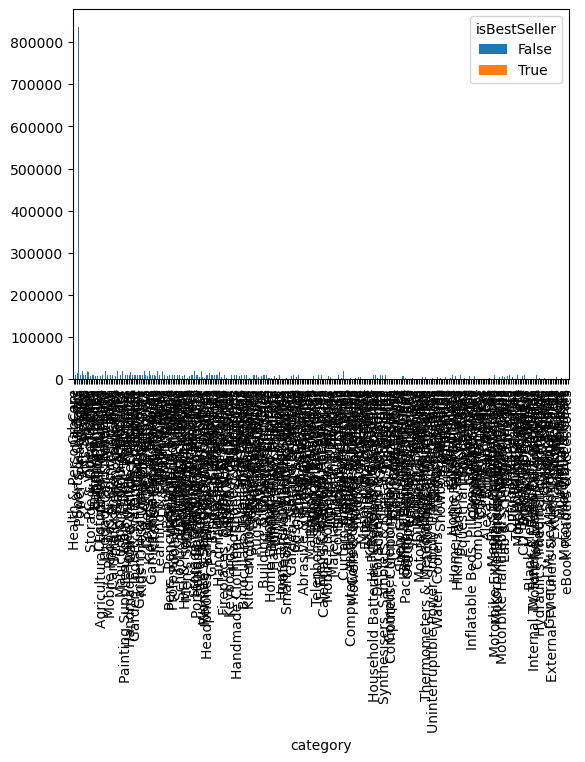

In [11]:
crosstab_result.plot(kind="bar", stacked=True)

# Part 2: 

## Exploring Product Prices and Ratings Across Categories and Brands
**Objective: Investigate how different product categories influence product prices.**

**Preliminary Step: Remove outliers in product prices.**

- For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.
- Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.

**Bar Charts:**

- Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
- Which product category commands the highest average price? Don't filter here by top categories.

**Violin Plots:**

- Use a violin plot to visualize the distribution of price across different product categories. Filter out the top 20 categories based on count for better visualization.
- Which product category commands the highest average price? Don't filter here by top categories.

**Box Plots:**

- Visualize the distribution of product ratings based on their category using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
- Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

### Preliminary Step: Remove outliers in product prices.

In [13]:
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

lower_whisker = Q1 - 1.5 * IQR
upper_whisker = Q3 + 1.5 * IQR
    
cleaned_data = df[(df['price'] > lower_whisker) & (df['price'] < upper_whisker)]
cleaned_data

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [19]:
IQR1 = df['price'].quantile(0.25)
IQR3 = df['price'].quantile(0.75)

IQR = IQR3 - IQR1

lower_bound = IQR1 - 1.5*IQR
upper_bound = IQR3 + 1.5*IQR

df = df[(df['price'] > lower_bound) & (df['price'] < upper_bound)]
df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [14]:
IQR

36.0

In [15]:
Q1,Q3

(9.99, 45.99)

In [ ]:
lower_whisker

### Violin Plots

In [20]:
top_20_category = cleaned_data['category'].value_counts().sort_values(ascending = False).head(20).index
top_20_category

Index(['Sports & Outdoors', 'Beauty', 'Bath & Body',
       'Manicure & Pedicure Products',
       'Handmade Clothing, Shoes & Accessories', 'Make-up', 'Skin Care',
       'Hair Care', 'Birthday Gifts', 'Handmade Gifts', 'Handmade Home Décor',
       'Luggage and travel gear', 'Women', 'Fragrances',
       'Handmade Kitchen & Dining', 'Handmade Artwork',
       'Handmade Home & Kitchen Products', 'Handmade Jewellery', 'Men',
       'Baby'],
      dtype='object')

In [21]:
df_top_20 = cleaned_data[cleaned_data['category'].isin(top_20_category)]
df_top_20

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
19513,21072,B09477KHQ3,"Personalised Birthday Print Gift ""THE YEAR YOU...",4.5,763,7.99,False,900,Handmade Home & Kitchen Products
19514,21073,B0BSRFQYG8,Wax Melts 4 Bars | Build Your Own Box (Choose ...,3.9,117,6.49,True,800,Handmade Home & Kitchen Products
19515,21074,B09N9GVHV9,"Personalised Birthday Print Gift ""ON THE DAY/Y...",4.6,1155,8.99,True,600,Handmade Home & Kitchen Products
19516,21075,B0BRYGV7PQ,Fresh Wax Melts - Laundry Type Wax Melts - Str...,4.5,56,4.99,True,500,Handmade Home & Kitchen Products
19517,21076,B0B1JHB28R,Manta Makes Work Leaving Gifts | I Used to Wor...,4.7,261,9.95,True,400,Handmade Home & Kitchen Products
...,...,...,...,...,...,...,...,...,...
2429088,2806950,B0045I6SHW,Cannondale Men's Bibshort Dart Team Bike Shorts,0.0,0,99.67,False,0,Sports & Outdoors
2429089,2806951,B0045I6NZY,Cannondale Men's Baggy Fitness Bike Shorts,0.0,0,20.62,False,0,Sports & Outdoors
2429090,2806952,B003BLON3A,Pearl iZUMi Men's Phase Splice Knicker,4.3,3,59.86,False,0,Sports & Outdoors
2437153,2818782,B091HG57TP,Goodstoworld Boys Girls Tracksuit Bottoms 3D S...,4.2,554,14.99,False,0,Sports & Outdoors


([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19],
 [Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, '')])

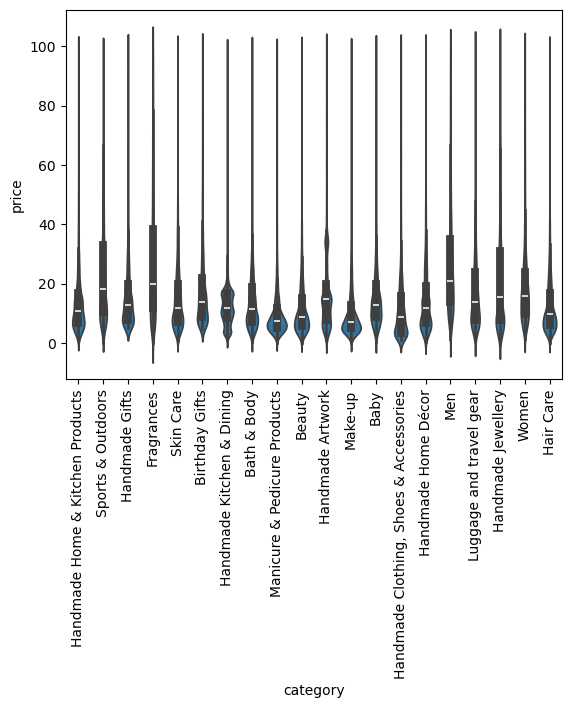

In [22]:
sns.violinplot( x=df_top_20['category'], y=df_top_20['price'])
plt.xticks(rotation=90)

In [23]:
df_top_20.groupby('category')['price'].agg('mean').sort_values(ascending = False)

category
Fragrances                                28.544912
Men                                       27.461174
Sports & Outdoors                         25.172065
Handmade Jewellery                        22.801007
Women                                     20.408735
Luggage and travel gear                   19.718228
Birthday Gifts                            18.600195
Handmade Artwork                          17.461758
Handmade Gifts                            17.395112
Baby                                      16.389799
Skin Care                                 15.654722
Handmade Home Décor                       15.413691
Bath & Body                               14.678683
Handmade Home & Kitchen Products          14.079947
Hair Care                                 13.461408
Handmade Kitchen & Dining                 13.119728
Handmade Clothing, Shoes & Accessories    12.958639
Beauty                                    12.523480
Make-up                                   10.612918
Man

### Box Plots:

- Visualize the distribution of product ratings based on their category using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
- Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

In [25]:
top_10_category = cleaned_data['category'].value_counts().sort_values(ascending = False).head(10).index
df_top_10 = cleaned_data[cleaned_data['category'].isin(top_10_category)]
df_top_10

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
82163,89483,B07DLGZ828,Neutrade GoPro 3M Sticky Pads Double Sided Adh...,4.2,3116,6.49,False,0,Sports & Outdoors
82164,89484,B09HGZHXJT,"WOLFANG Action Camera 4K 20MP GA100, Waterproo...",4.2,2594,49.99,False,0,Sports & Outdoors
82167,89487,B08LD4VXGL,FitStill 60M/196FT Waterproof Case for Go Pro ...,4.5,9879,16.98,True,0,Sports & Outdoors
82168,89488,B07QDMLMJH,Nextbase Powered Mount Variations For Cameras ...,4.7,1223,19.95,False,0,Sports & Outdoors
82169,89489,B09TQMCNY7,WOLFANG Action Camera GA100 with 64GB microSDX...,4.2,55,49.99,False,0,Sports & Outdoors
...,...,...,...,...,...,...,...,...,...
2429088,2806950,B0045I6SHW,Cannondale Men's Bibshort Dart Team Bike Shorts,0.0,0,99.67,False,0,Sports & Outdoors
2429089,2806951,B0045I6NZY,Cannondale Men's Baggy Fitness Bike Shorts,0.0,0,20.62,False,0,Sports & Outdoors
2429090,2806952,B003BLON3A,Pearl iZUMi Men's Phase Splice Knicker,4.3,3,59.86,False,0,Sports & Outdoors
2437153,2818782,B091HG57TP,Goodstoworld Boys Girls Tracksuit Bottoms 3D S...,4.2,554,14.99,False,0,Sports & Outdoors


C:\Users\ramya\AppData\Local\Temp\ipykernel_13636\3270093780.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  boxplot = sns.boxplot(x=df_top_10['category'], y=df_top_10['stars'], palette="coolwarm")


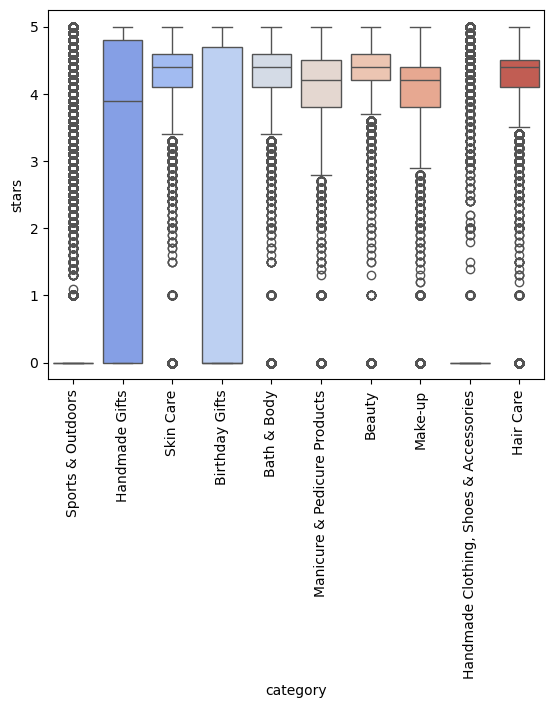

In [26]:
boxplot = sns.boxplot(x=df_top_10['category'], y=df_top_10['stars'], palette="coolwarm")
plt.xticks(rotation=90)
plt.show()

In [27]:
cleaned_data.groupby('category')['stars'].agg('median').sort_values(ascending = False).head(20)

category
Computer Memory                     4.7
Building & Construction Toys        4.6
Office Paper Products               4.6
Luxury Food & Drink                 4.6
Kids' Play Figures                  4.6
Hobbies                             4.6
Beer, Wine & Spirits                4.6
Laptop Accessories                  4.6
Cables & Accessories                4.5
CPUs                                4.5
Soft Toys                           4.5
Health & Personal Care              4.5
Film Cameras                        4.5
Boxes & Organisers                  4.5
Children's Bedding                  4.5
School & Educational Supplies       4.5
Computer & Server Racks             4.5
Pens, Pencils & Writing Supplies    4.5
Dolls & Accessories                 4.5
Camera & Photo Accessories          4.5
Name: stars, dtype: float64

### Bar Plots:

C:\Users\ramya\AppData\Local\Temp\ipykernel_13636\2090246948.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data = df_top_10, x = 'category', y = 'price', palette="coolwarm")


([0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
 [Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, ''),
  Text(0, 0, '')])

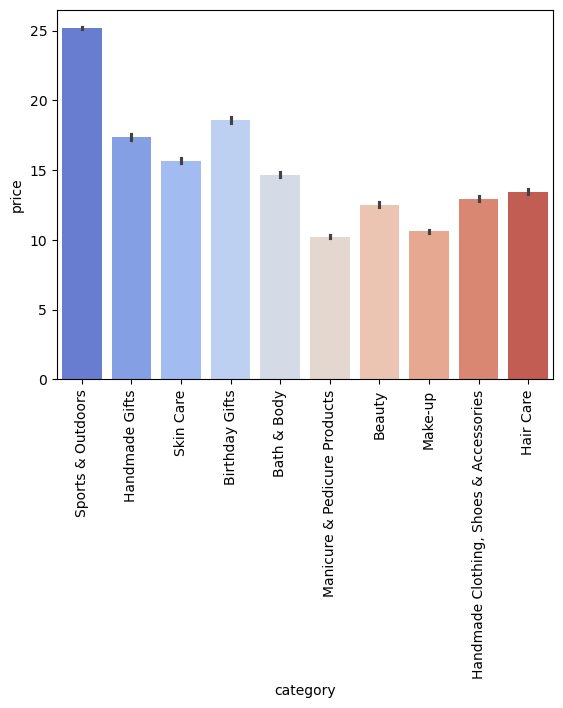

In [28]:
sns.barplot(data = df_top_10, x = 'category', y = 'price', palette="coolwarm")
plt.xticks(rotation = 90)

# Part 3: 
## Investigating the Interplay Between Product Prices and Ratings

**Objective:** 
    Analyze how product ratings (stars) correlate with product prices.

**Correlation Coefficients:**

- Calculate the correlation coefficient between price and stars.
- Is there a significant correlation between product price and its rating?

**Visualizations:**

- Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
- Use a correlation heatmap to visualize correlations between all numerical variables.
- Examine if product prices typically follow a normal distribution using a QQ plot.


In [29]:
correlation = cleaned_data['stars'].corr(cleaned_data['price'])
correlation

-0.07767299878181445

In [30]:
correlation = cleaned_data['stars'].corr(cleaned_data['price'], method='spearman')
correlation

-0.06679697280768455

- Pearson Correlation: (-0.08)
    - a very weak negative linear relationship between the two variables
- Spearman Correlation: (-0.07)
    - a very weak negative monotonic relationship between the two variables

<AxesSubplot:xlabel='stars', ylabel='price'>

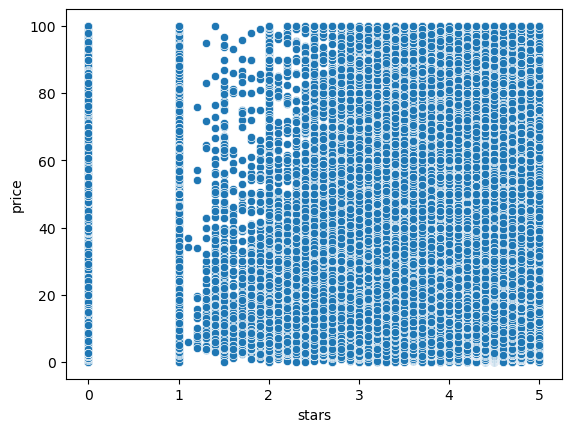

In [31]:
sns.scatterplot(data=cleaned_data, x='stars', y='price')

In [32]:
df_numerical = cleaned_data.select_dtypes('number').drop(columns = ['boughtInLastMonth', 'uid'])
df_numerical

,stars,reviews,price
0,4.7,15308,21.99
1,4.7,98099,23.99
2,4.7,15308,21.99
3,4.7,7205,31.99
4,4.6,1881,17.99
...,...,...,...
2443646,0.0,0,22.34
2443647,0.0,0,97.99
2443648,0.0,0,52.99
2443649,4.3,404,79.99


In [33]:
df_numerical.corr()

,stars,reviews,price
stars,1.000000,0.083920,-0.077673
reviews,0.083920,1.000000,-0.008498
price,-0.077673,-0.008498,1.000000


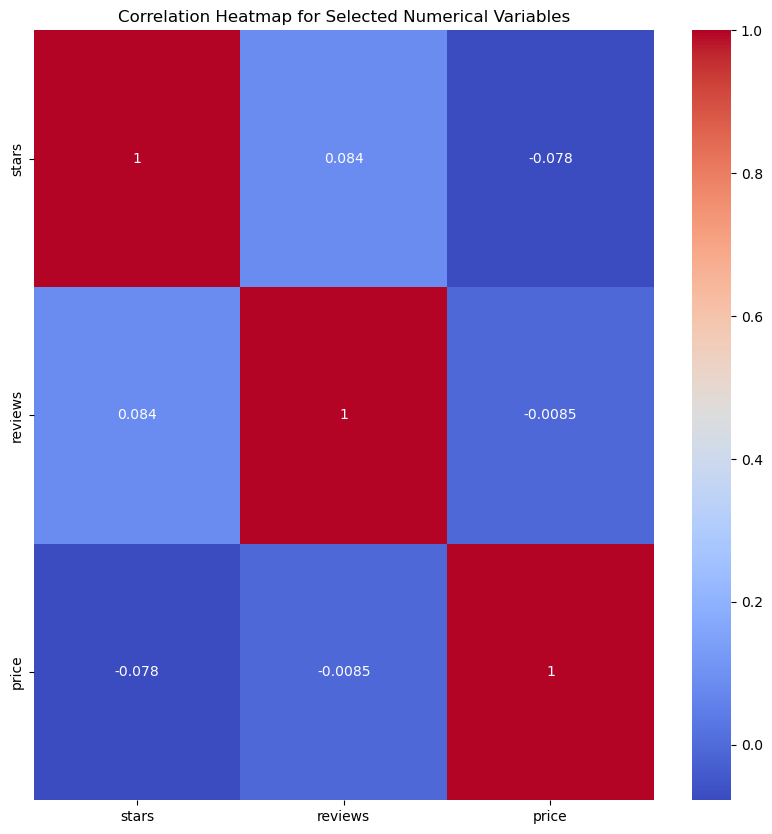

In [36]:
correlation_matrix = df_numerical.corr()

plt.figure(figsize=(10, 10))

sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm")

plt.title("Correlation Heatmap for Selected Numerical Variables")
plt.show()

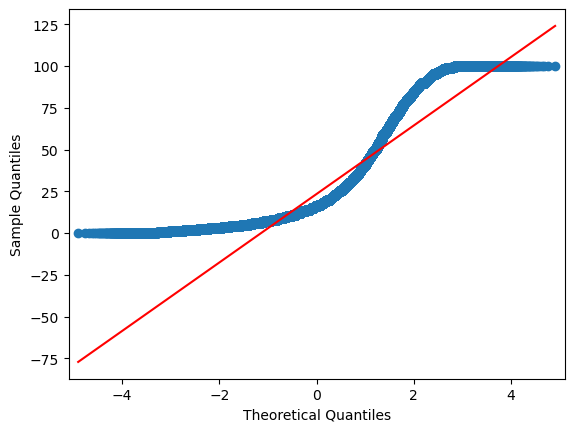

In [35]:
import statsmodels.api as sm

sm.qqplot(cleaned_data['price'], line='s');